# HR Employee Attrition Prediction
**Task:** Binary classification - predict whether an employee will leave the company (`left` = 1) or stay (`left` = 0).

**Workflow:** Load data -> EDA -> Cleaning -> Train/Test split -> Outlier handling -> Preprocessing pipeline -> Modelling (Logistic Regression, KNN, SVC, Decision Tree, Random Forest) -> Model comparison -> Save `.pkl` for FastAPI deployment.

## 1. Import Libraries

In [1]:
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

## 2. Load Dataset


In [2]:
df = pd.read_csv('HR_comma_sep.csv')
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [4]:
df.shape

(14999, 10)

## Data Understanding

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
satisfaction_level,14999.0,0.612834,0.248631,0.09,0.44,0.64,0.82,1.0
last_evaluation,14999.0,0.716102,0.171169,0.36,0.56,0.72,0.87,1.0
number_project,14999.0,3.803054,1.232592,2.00,3.00,4.00,5.00,7.0
average_montly_hours,14999.0,201.050337,49.943099,96.00,156.00,200.00,245.00,310.0
time_spend_company,14999.0,3.498233,1.460136,2.00,3.00,3.00,4.00,10.0
Work_accident,14999.0,0.144610,0.351719,0.00,0.00,0.00,0.00,1.0
left,14999.0,0.238083,0.425924,0.00,0.00,0.00,0.00,1.0
promotion_last_5years,14999.0,0.021268,0.144281,0.00,0.00,0.00,0.00,1.0


In [12]:
# Findint the missing and duplicate
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows :', df.duplicated().sum())

Missing values: 0
Duplicate rows : 3008


## 4. Data Cleaning


In [13]:
df = df.rename(columns={
    'average_montly_hours': 'average_monthly_hours',
    'sales': 'department',
    'time_spend_company': 'years_at_company',
    'Work_accident': 'work_accident',
    'promotion_last_5years': 'promotion_last_5years'
})
df = df.drop_duplicates().reset_index(drop=True)

In [17]:
# after clean
df.shape

(11991, 10)

In [18]:
df.head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,years_at_company,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Exploratory Data Analysis(EDA)

##Target distribution

left
0    10000
1     1991
Name: count, dtype: int64
left
0    0.834
1    0.166
Name: proportion, dtype: float64


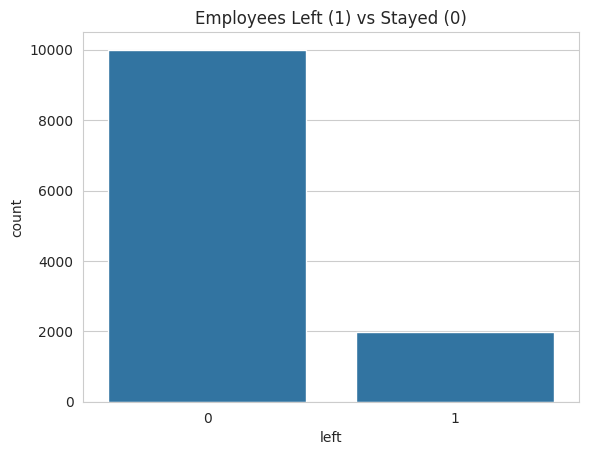

In [19]:
print(df['left'].value_counts())
print(df['left'].value_counts(normalize=True).round(3))
sns.countplot(data=df, x='left')
plt.title('Employees Left (1) vs Stayed (0)')
plt.show()

### Categorical features vs target

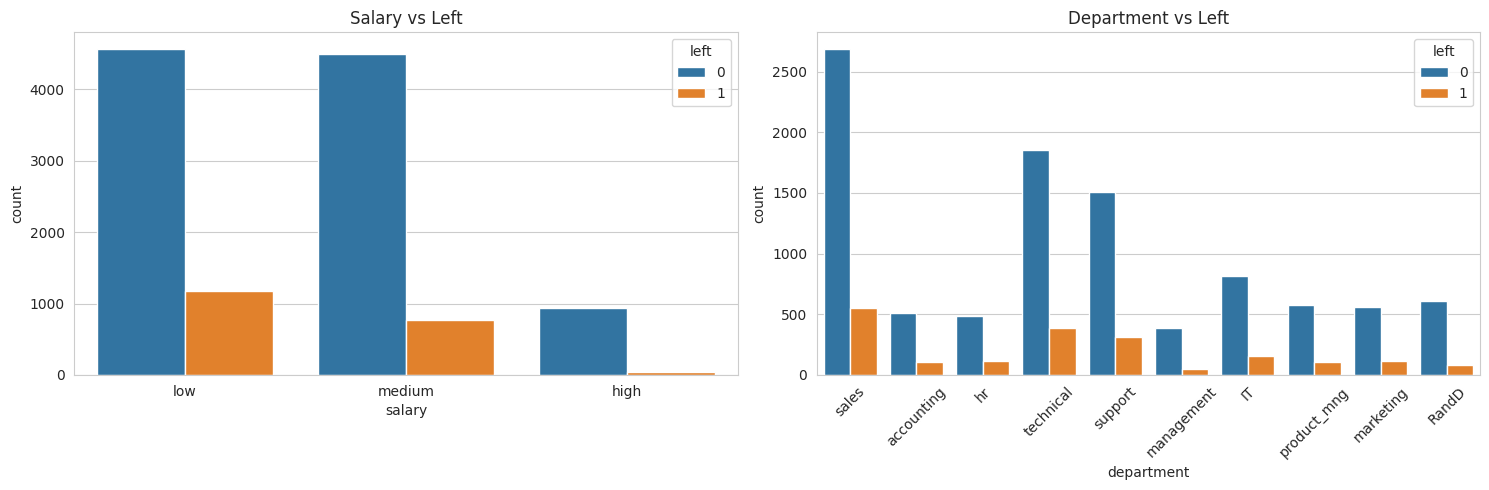

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x='salary', hue='left', order=['low', 'medium', 'high'], ax=axes[0])
axes[0].set_title('Salary vs Left')
sns.countplot(data=df, x='department', hue='left', ax=axes[1])
axes[1].set_title('Department vs Left')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

##Numerical features vs target

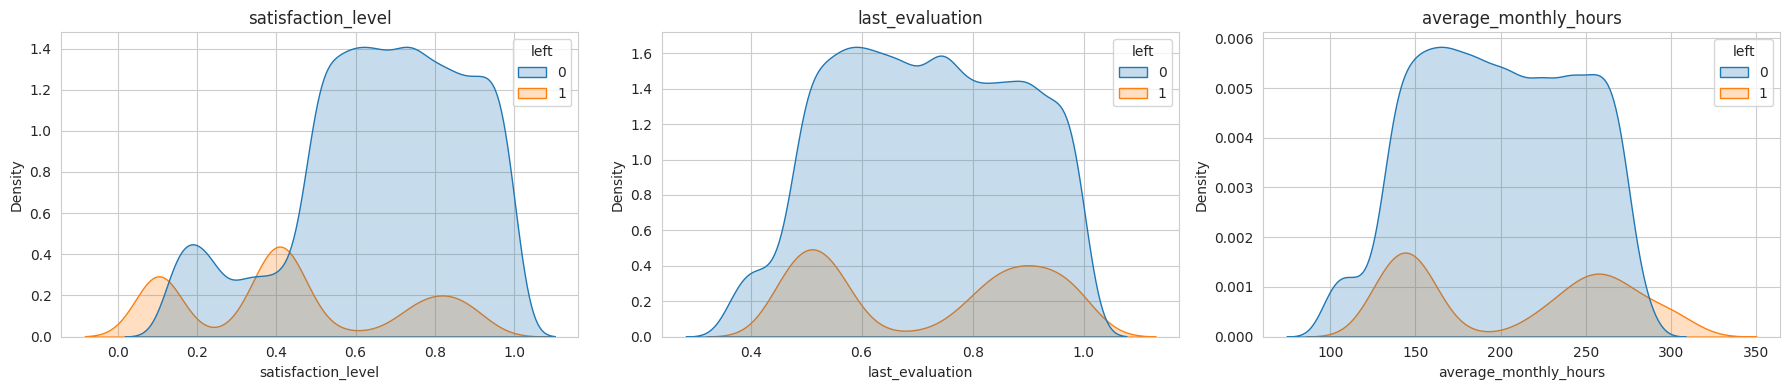

In [21]:
num_cols_plot = ['satisfaction_level', 'last_evaluation', 'average_monthly_hours']
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, num_cols_plot):
    sns.kdeplot(data=df, x=col, hue='left', fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

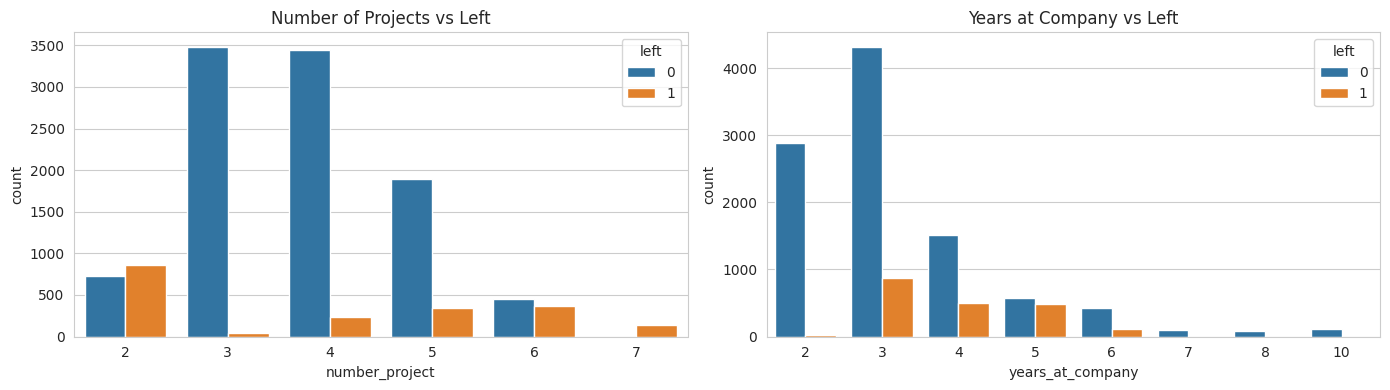

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, x='number_project', hue='left', ax=axes[0])
axes[0].set_title('Number of Projects vs Left')
sns.countplot(data=df, x='years_at_company', hue='left', ax=axes[1])
axes[1].set_title('Years at Company vs Left')
plt.tight_layout()
plt.show()

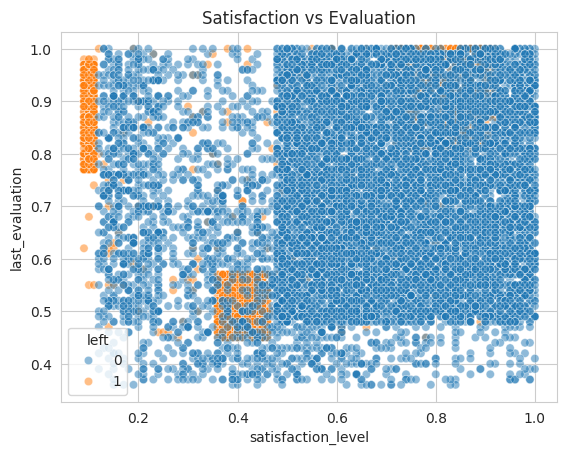

In [23]:
sns.scatterplot(data=df, x='satisfaction_level', y='last_evaluation', hue='left', alpha=0.5)
plt.title('Satisfaction vs Evaluation')
plt.show()

##Correlation heatmap

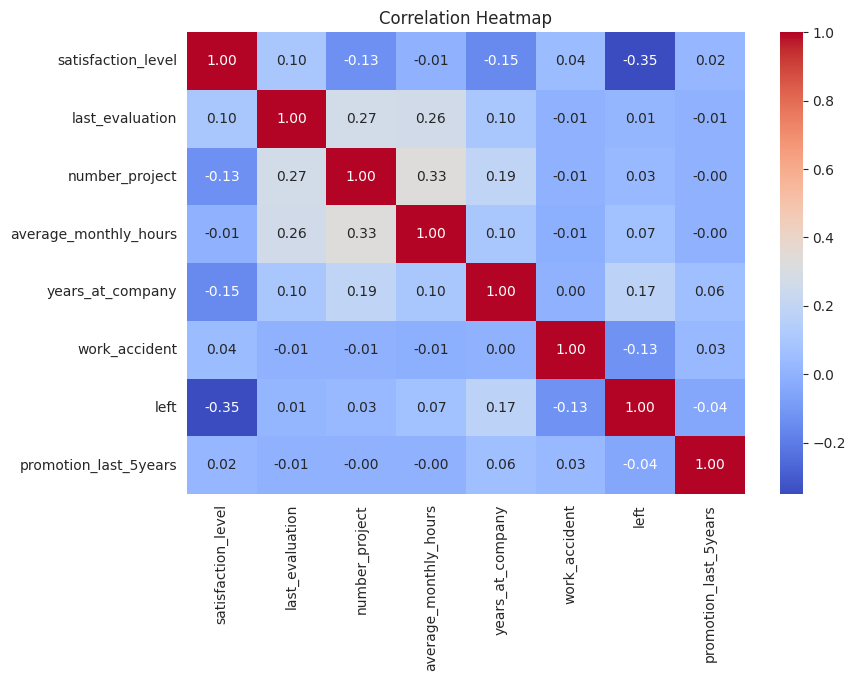

In [24]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

##Outlier find

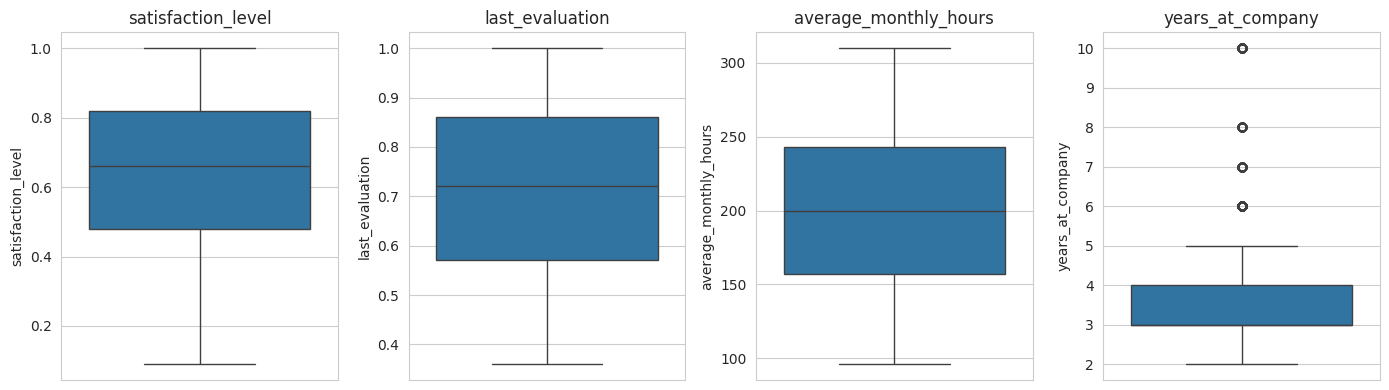

In [25]:
plt.figure(figsize=(14, 4))
for i, col in enumerate(['satisfaction_level', 'last_evaluation', 'average_monthly_hours', 'years_at_company']):
    plt.subplot(1, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

## Train Test Split

In [27]:
X = df.drop('left', axis=1)
y = df['left']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [28]:
print(X_train.shape, X_test.shape)

(9592, 9) (2399, 9)


##Outlier Handling

In [29]:
q1 = X_train['years_at_company'].quantile(0.25)
q3 = X_train['years_at_company'].quantile(0.75)

iqr = q3 - q1
years_min = max(0, q1 - 1.5 * iqr)
years_max = q3 + 1.5 * iqr

print('Allowed range:', years_min, '-', years_max)

X_train['years_at_company'] = X_train['years_at_company'].clip(years_min, years_max)

X_test['years_at_company'] = X_test['years_at_company'].clip(years_min, years_max)

Allowed range: 1.5 - 5.5


## Feature Engineering


In [36]:
def add_features(data):
    data = data.copy()
    data['hours_per_project'] = data['average_monthly_hours'] / data['number_project']
    return data

X_train = add_features(X_train)
X_test = add_features(X_test)
X_train.head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,years_at_company,work_accident,promotion_last_5years,department,salary,hours_per_project
2032,0.98,0.91,4,240,3.0,0,0,technical,low,60.000000
10435,0.63,0.89,3,239,3.0,0,0,IT,medium,79.666667
2021,0.85,0.59,3,235,3.0,0,0,support,low,78.333333
11597,0.56,0.39,3,106,5.5,0,0,management,high,35.333333
1999,0.50,0.75,6,127,3.0,0,0,sales,low,21.166667


## 9. Preprocessing Pipeline

In [30]:
categories = [['low', 'medium', 'high']]


In [31]:
p_standard = Pipeline(steps=[('scaler', StandardScaler())])
p_robust = Pipeline(steps=[('scaler', RobustScaler())])
p_minmax = Pipeline(steps=[('scaler', MinMaxScaler())])

In [33]:
p_nominal = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore'))
])



p_ordinal = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=categories)),
    ('scaler', MinMaxScaler())
])



preprocessor = ColumnTransformer(
    transformers=[
        ('num_normal', p_standard, ['satisfaction_level', 'last_evaluation', 'average_monthly_hours', 'hours_per_project']),
        ('num_outlier', p_robust, ['years_at_company']),
        ('num_bounded', p_minmax, ['number_project']),
        ('nominal', p_nominal, ['department']),
        ('ordinal', p_ordinal, ['salary']),
    ],
    remainder='passthrough'
)

preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('num_normal',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['satisfaction_level', 'last_evaluation',
                                  'average_monthly_hours',
                                  'hours_per_project']),
                                ('num_outlier',
                                 Pipeline(steps=[('scaler', RobustScaler())]),
                                 ['years_at_company']),
                                ('num_bounded',
                                 Pipeline(steps=[('scaler', MinMaxScaler())]),
                                 ['number...
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['department']),
                                ('ordinal',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OrdinalEncoder(categories=[['low',
                                                                              'medium',
                                                                              'high']])),
                                                 ('scaler', MinMaxScaler())]),
                                 ['salary'])])

## Modelling


In [34]:
results = []

def evaluate(name, model):
    y_pred = model.predict(X_test)
    y_train_pred = model.predict(X_train)
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)
    row = {
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, y_train_pred),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_score),
    }
    results.append(row)
    print(classification_report(y_test, y_pred))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
    plt.title(name)
    plt.show()

### 10.1 Logistic Regression

              precision    recall  f1-score   support

           0       0.97      0.79      0.87      2001
           1       0.45      0.89      0.60       398

    accuracy                           0.80      2399
   macro avg       0.71      0.84      0.73      2399
weighted avg       0.89      0.80      0.82      2399



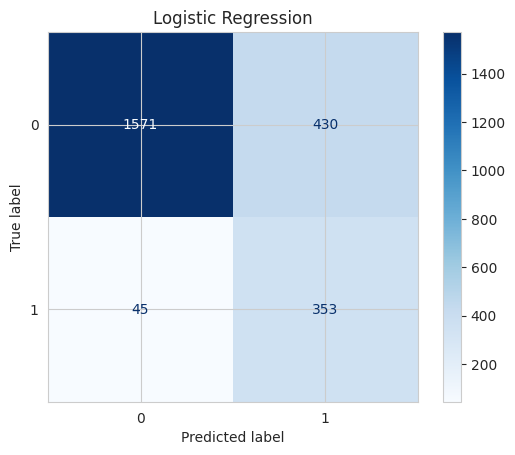

In [37]:
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000))
])
lr_model.fit(X_train, y_train)
evaluate('Logistic Regression', lr_model)

###K-Nearest Neighbours (GridSearchCV)

Best params: {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance'}
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      2001
           1       0.89      0.93      0.91       398

    accuracy                           0.97      2399
   macro avg       0.94      0.95      0.94      2399
weighted avg       0.97      0.97      0.97      2399



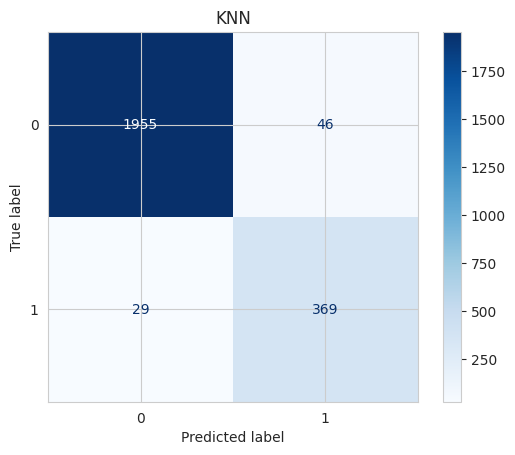

In [38]:
knn_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])
knn_grid = {
    'model__n_neighbors': [5, 11, 15],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}
knn_search = GridSearchCV(knn_pipe, knn_grid, cv=5, scoring='f1', n_jobs=-1)

knn_search.fit(X_train, y_train)

print('Best params:', knn_search.best_params_)

evaluate('KNN', knn_search.best_estimator_)

##Support Vector Classifier (GridSearchCV)

Best params: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      2001
           1       0.89      0.93      0.91       398

    accuracy                           0.97      2399
   macro avg       0.94      0.95      0.94      2399
weighted avg       0.97      0.97      0.97      2399



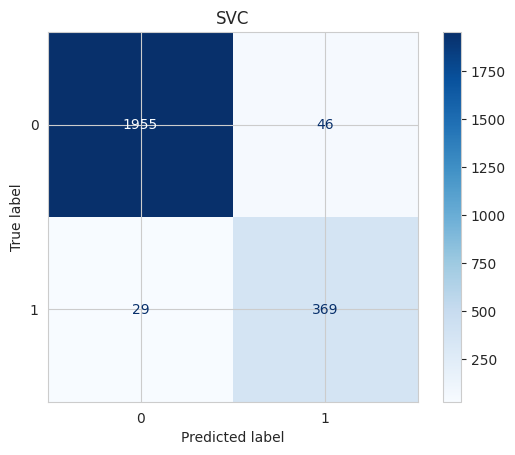

In [39]:
svc_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', SVC(class_weight='balanced', random_state=42))
])
svc_grid = [
    {'model__kernel': ['linear'], 'model__C': [0.1, 1]},
    {'model__kernel': ['rbf'], 'model__C': [1, 10], 'model__gamma': ['scale', 0.1]},
]
svc_search = GridSearchCV(svc_pipe, svc_grid, cv=5, scoring='f1', n_jobs=-1)
svc_search.fit(X_train, y_train)
print('Best params:', svc_search.best_params_)
evaluate('SVC', svc_search.best_estimator_)

### Decision Tree (GridSearchCV)

Best params: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 1}
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2001
           1       0.95      0.92      0.94       398

    accuracy                           0.98      2399
   macro avg       0.97      0.96      0.96      2399
weighted avg       0.98      0.98      0.98      2399



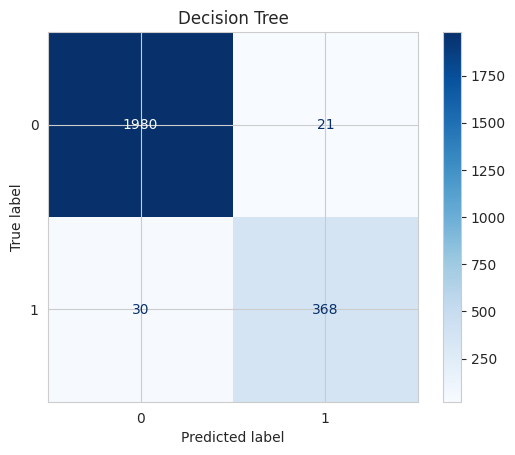

In [40]:
dt_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])
dt_grid = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 4, 5, 6, 7, 8, 10, None],
    'model__min_samples_leaf': [1, 5, 10]
}
dt_search = GridSearchCV(dt_pipe, dt_grid, cv=5, scoring='f1', n_jobs=-1)
dt_search.fit(X_train, y_train)
print('Best params:', dt_search.best_params_)
evaluate('Decision Tree', dt_search.best_estimator_)

##Random Forest (GridSearchCV)

Best params: {'model__criterion': 'entropy', 'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__n_estimators': 200}
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2001
           1       0.98      0.92      0.95       398

    accuracy                           0.98      2399
   macro avg       0.98      0.96      0.97      2399
weighted avg       0.98      0.98      0.98      2399



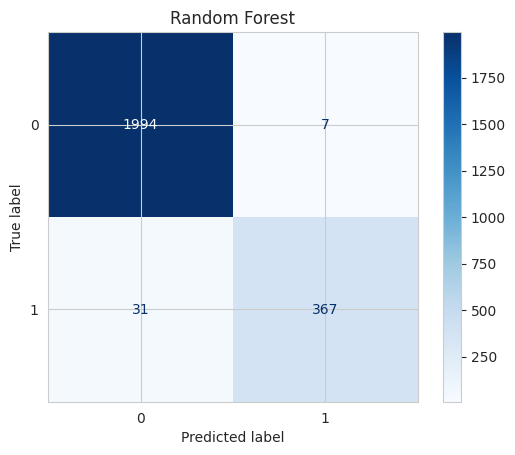

In [41]:
rf_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
])
rf_grid = {
    'model__n_estimators': [100, 200],
    'model__criterion': ['gini', 'entropy'],
    'model__max_features': ['sqrt'],
    'model__max_depth': [10, None]
}
rf_search = GridSearchCV(rf_pipe, rf_grid, cv=5, scoring='f1', n_jobs=-1)
rf_search.fit(X_train, y_train)
print('Best params:', rf_search.best_params_)
evaluate('Random Forest', rf_search.best_estimator_)

##Model Comparison

In [43]:
results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df.sort_values('F1', ascending=False)

,Train Accuracy,Test Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,,
Random Forest,0.9873,0.9842,0.9813,0.9221,0.9508,0.9802
Decision Tree,0.9793,0.9787,0.9460,0.9246,0.9352,0.9773
SVC,0.9807,0.9687,0.8892,0.9271,0.9077,0.9736
KNN,1.0000,0.9687,0.8892,0.9271,0.9077,0.9650
Logistic Regression,0.7909,0.8020,0.4508,0.8869,0.5978,0.8611


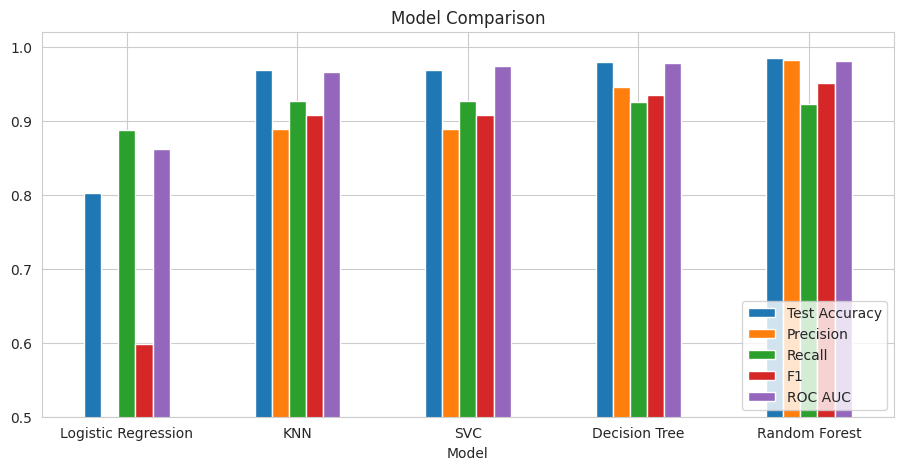

In [44]:
results_df[['Test Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']].plot(kind='bar', figsize=(11, 5))
plt.title('Model Comparison')
plt.ylim(0.5, 1.02)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

##Save Model for Deployment

In [45]:
best_rf_model = rf_search.best_estimator_

# Save the model pipeline to a file
model_filename = 'best_rf_model.pkl'
joblib.dump(best_rf_model, model_filename)
print(f"Successfully saved the model pipeline to '{model_filename}'!")

Successfully saved the model pipeline to 'best_rf_model.pkl'!


In [46]:
from google.colab import files

files.download('best_rf_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>